# 2.4 Colonisation image coverage (**Photo coverage**)
Rough first version of photo → % colonised for d005. The `coverage` function now lives in `mycodemo/growth/coverage.py` (shared with the app). S, W and FD genuinely barely grew.

### Cell 1. Imports and paths

In [1]:
import re
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from mycodemo.config import EXTERNAL_DATA_DIR, INTERIM_DATA_DIR
from mycodemo.growth.coverage import coverage

GROWTH_DIR = EXTERNAL_DATA_DIR / "d005_elsacker2019" / "02_Growth images"

2026-10-11 19:19:04.680 | INFO     | mycodemo.config:<module>:11 - PROJ_ROOT path is: /home/sylas/Desktop/mycodemo


### Cell 2. Coverage of one photo

In [2]:
# coverage(path) is imported from mycodemo.growth.coverage in cell 1
coverage

### Cell 3. Every dated photo of every dish → one table

In [3]:
rows = []
for dish_dir in sorted(p for p in GROWTH_DIR.iterdir() if p.is_dir()):
    for f in sorted(dish_dir.glob("*_Tv_*.jpg")):
        # name like H_0004_180215_H_Tv_180221.png.jpg -> start 180215, photo 180221
        m = re.search(r"_(\d{6})_.*_Tv_(\d{6})", f.name)
        if not m:
            continue
        start = datetime.strptime(m.group(1), "%y%m%d")
        taken = datetime.strptime(m.group(2), "%y%m%d")
        rows.append({"series_id": f"d005-{dish_dir.name}", "dataset": "d005",
                     "day": (taken - start).days, "coverage": coverage(f),
                     "file": f.name})
cov = pd.DataFrame(rows)
cov.groupby("series_id").size()

series_id
d005-FD      9
d005-FLT     8
d005-FLU     8
d005-FSW     8
d005-Flax    8
d005-H       9
d005-S       9
d005-W       8
dtype: int64

### Cell 4. Look at it

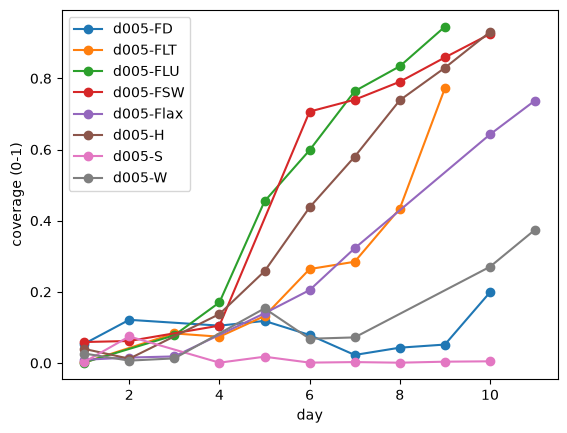

In [4]:
for sid, g in cov.groupby("series_id"):
    plt.plot(g["day"], g["coverage"], "o-", label=sid)
plt.xlabel("day"); plt.ylabel("coverage (0-1)"); plt.legend(); plt.show()

### Cell 5. Save the table** (a new file, `data/interim/coverage_auto.csv`, which the next notebook reads)

In [5]:
cov.to_csv(INTERIM_DATA_DIR / "coverage_auto.csv", index=False)